In [11]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import yfinance as yf 

In [12]:
nifty_index=yf.download("^NSEI",period="max",interval="1d")

[*********************100%***********************]  1 of 1 completed


In [13]:
nifty_index.describe()

Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
count,4682.000000,4682.000000,4682.000000,4682.000000,4.682000e+03
mean,11465.209916,11531.217245,11396.566282,11471.562635,2.186467e+05
std,6743.764343,6766.538620,6720.117385,6746.070380,2.057098e+05
min,2524.199951,2585.300049,2252.750000,2553.600098,0.000000e+00
25%,5742.299805,5790.800049,5691.075073,5748.200195,0.000000e+00
50%,9075.674805,9130.024902,8982.600098,9090.050293,1.968000e+05
75%,17012.612305,17144.937988,16915.324707,17059.250488,3.060000e+05
max,26328.550781,26373.199219,26210.050781,26333.699219,1.811000e+06


In [14]:
# Columns are multindexed so we need to remove '^NSEI' from the columns
nifty_index.columns=nifty_index.columns.droplevel(level=1)

# Removing duplicate dates
nifty_index = nifty_index[~nifty_index.index.get_level_values('Date').duplicated(keep='first')]

# Dropping Volume since it contains a lot of missing data
nifty_index=nifty_index.drop(columns="Volume")
print(nifty_index.columns)
nifty_index.to_csv('nifty_index.csv')


Index(['Close', 'High', 'Low', 'Open'], dtype='str', name='Price')


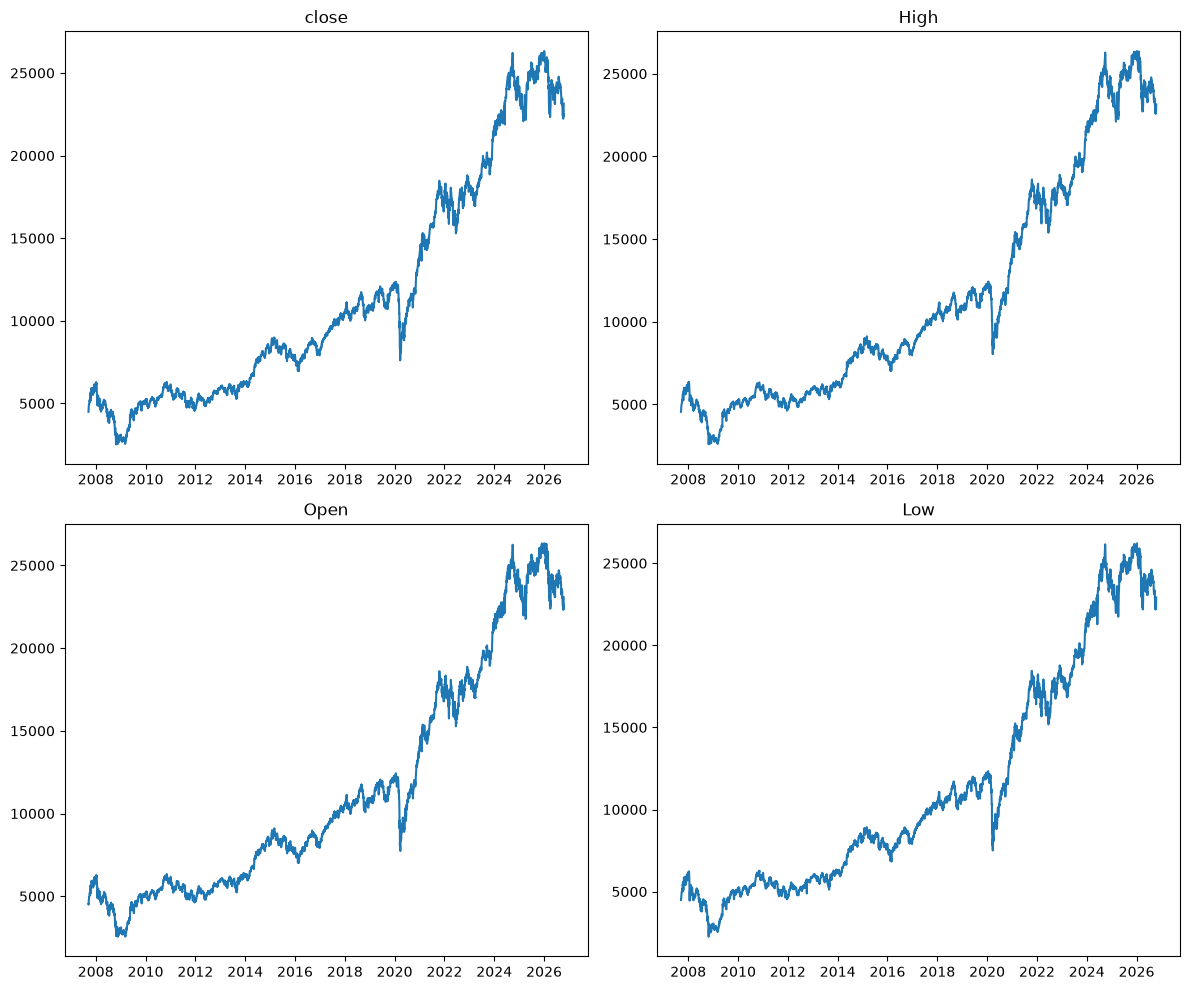

In [15]:
# Plots
fig,axs=plt.subplots(2,2,figsize=(12,10))

axs[0,0].plot(nifty_index["Close"])
axs[0,0].set_title("close")

axs[0,1].plot(nifty_index["High"])
axs[0,1].set_title("High")

axs[1,0].plot(nifty_index["Open"])
axs[1,0].set_title("Open")

axs[1,1].plot(nifty_index["Low"])
axs[1,1].set_title("Low")

plt.tight_layout()


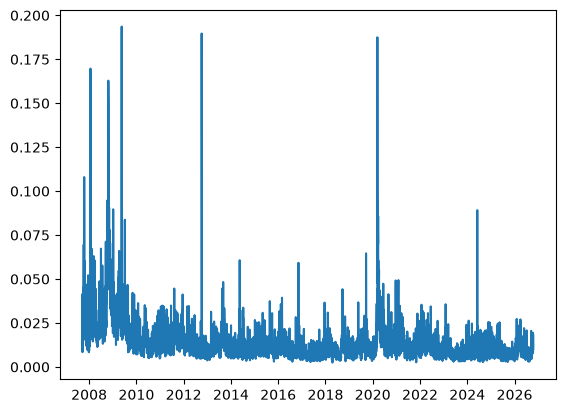

In [16]:
# How much higher High is compared to low
normalised_Range=(nifty_index["High"]-nifty_index["Low"])/(nifty_index["Low"])
plt.plot(normalised_Range)

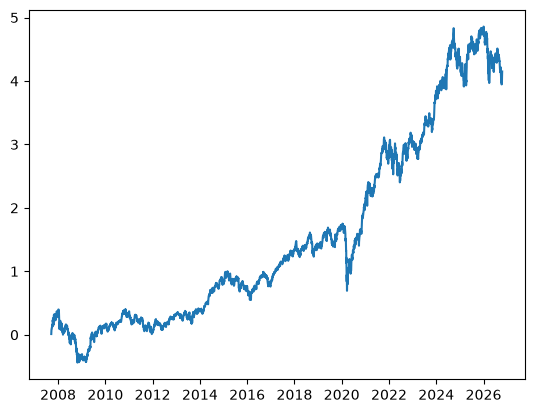

In [17]:
def returns(nifty_index):
    daily_returns = nifty_index["Close"].pct_change()
    return daily_returns

def cummulative_returns(daily_returns):
    cummulative_returns=(1+daily_returns).cumprod()-1
    return cummulative_returns

daily_returns=returns(nifty_index)
cummulative_returns=cummulative_returns(daily_returns)
plt.plot(cummulative_returns)
    

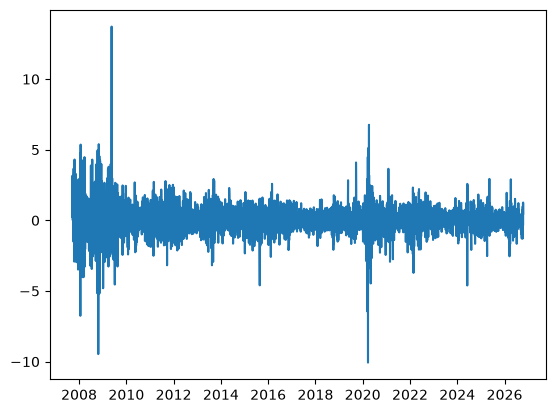

In [18]:
# Sharpe Signifies risk adjusted returns
# Sharpe = (average_return-riskfreereturn)/std_dev

def sharpe(daily_returns,risk_free_return=0.065):
    daily_risk_free_return=(1+risk_free_return)**(1/252) -1

    excess_returns=daily_returns-daily_risk_free_return

    average_return=excess_returns.mean()
    standard_deviation = excess_returns.std()

    daily_sharpe = excess_returns/standard_deviation   
    return daily_sharpe

sharpe=sharpe(daily_returns)
sharpe
plt.plot(sharpe)

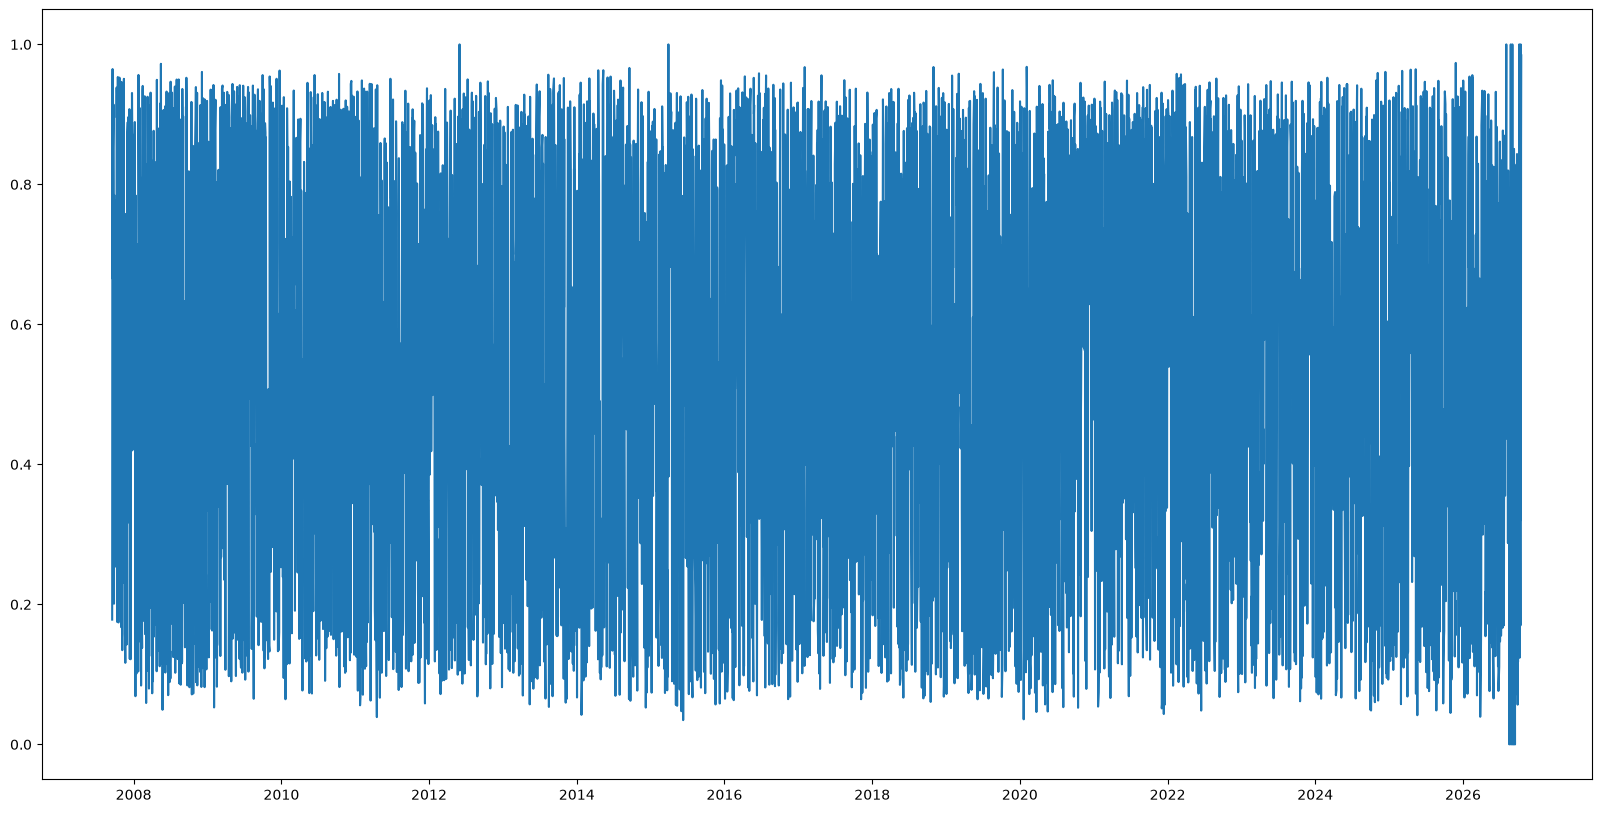

In [19]:
# Checking whether close is near high or low on daily basis
# we can use (high-close)/high-low
# gives a value in [0,1]

index=(nifty_index["Close"]-nifty_index["Low"])/(nifty_index["High"]-nifty_index["Low"])
plt.figure(figsize=(20,10))
plt.plot(index)



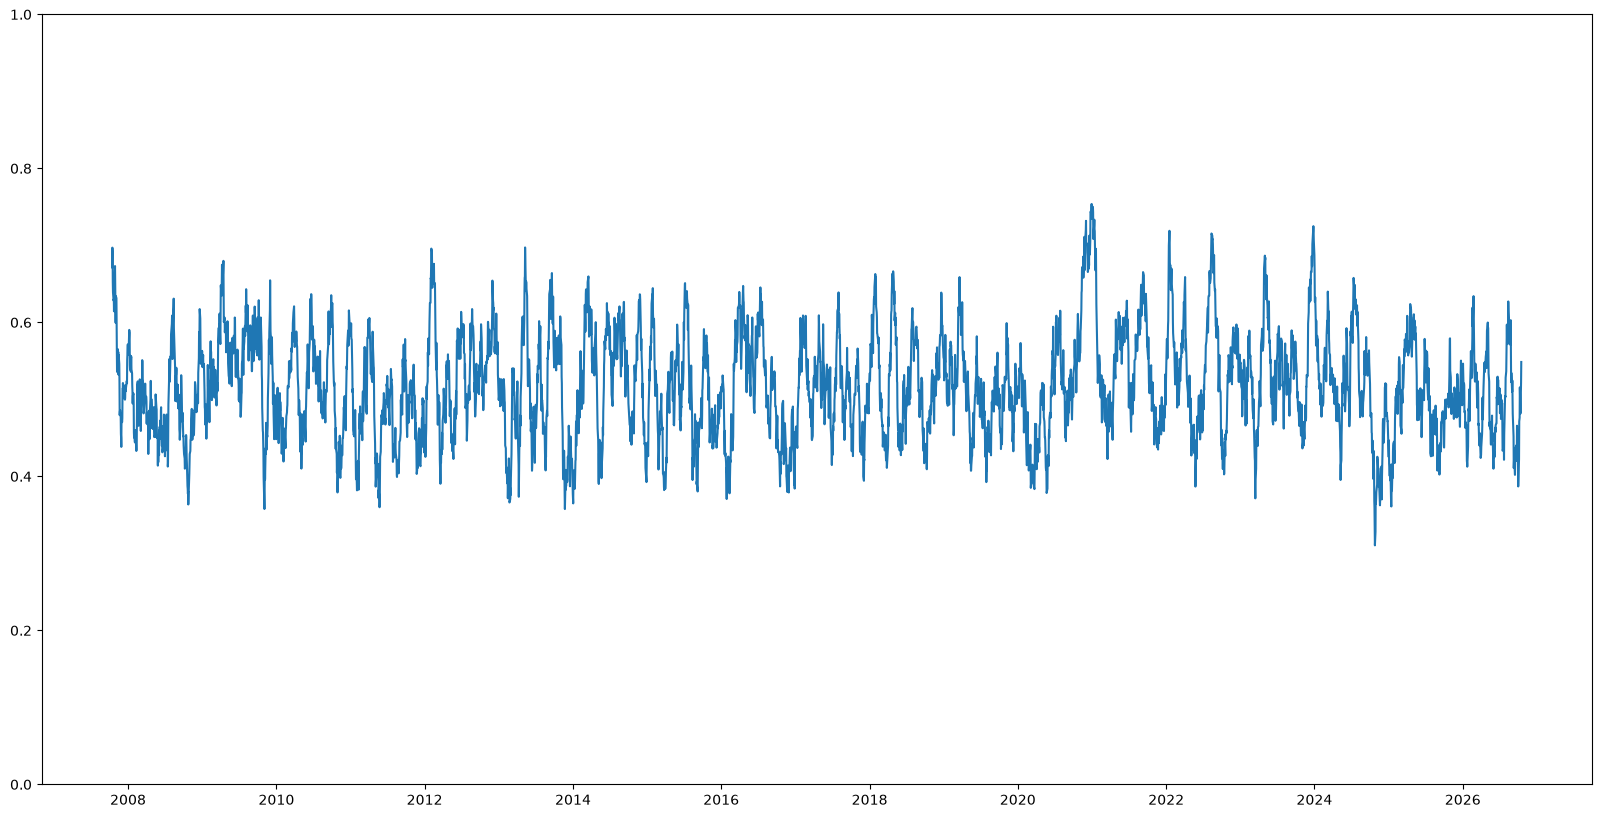

In [20]:
index.rolling(window=10).mean().dropna()
plt.figure(figsize=(20,10))
plt.ylim(0,1)
plt.plot(index.rolling(window=20).mean().dropna())
# Its almost averagely near 0.5
